# Does the particle clock roll over?

**A particle clock that wraps or crosses midnight turns one inter-arrival time into a large negative number, and the particle at the jump is lost**, removed as shattered or rejected as an inter-arrival failure (UIOOPS `sizeDist.m`'s code `'I'`). A wrong-sized correction is worse: a counter span applied to a midnight drop leaves the jump at -86391.6 s. The check reads only the per-particle time column, finds every backwards step and classifies it, so the right step is restored before processing; here the restored clock matches the true one exactly.

**What you get**

- every backwards step, classified as a midnight crossing (about 86400 s), a counter wrap or sub-second jitter;
- the effect on the inter-arrival histogram and the shattering count;
- the correction's idea, and a cell that runs the classifier on your own particle file.

> **Every number in this notebook is synthetic**, drawn from a fixed-seed random-number generator in section 2; no data file is read.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [09_shattering_interarrival_fit](09_shattering_interarrival_fit.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib) (`pip install "arrayprobe[zarr]"` adds an optional section).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. How the clock is corrected, and where it is not

`sizeDist.m:852-856` (UIOOPS v3.1.4) corrects a backwards inter-arrival time in a branch on the probe type:

| probe type | what the clock is | correction in the source |
|---|---|---|
| 0 (2DC/2DP) | 24-bit tick counter | every `int_arr < 0` gets `(2^24-1)*(res/10^6/tasMax)` added |
| 2 (2D-S, HVPS) | 32-bit tick counter | every `int_arr < -10` gets `(2^32-1)*(res/10^6/tasMax)` added |
| 1 (CIP/PIP) | decoded time of day | **none** |

Any value still negative is then rejected as `'I'` and set to 0 (`:748-749` of the field-campaign variant tree). A
probe-type-1 clock is a time of day, so its one rollover is **midnight, a drop of 86400 s**, and nothing
adds it back. The opt-in correction `int_arr_rollback_fix` (in the opt-in enhancements package, `pip install "arrayprobe[enhancements]"`) restores
monotonic time before `sizeDist` runs, by adding the step to every particle after each backwards jump.

## 2. A synthetic flight segment that crosses midnight

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(29)
n = 20_000
# Poisson arrivals at ~200 particles/s, plus 8 % shattering bursts of fragments 1-5 us apart.
gaps = rng.exponential(1 / 200.0, n)
burst = rng.random(n) < 0.08
gaps[burst] = rng.uniform(1e-6, 5e-6, burst.sum())
t_true = 86400.0 - 40.0 + np.cumsum(gaps)          # starts 40 s before midnight
t_clock = np.mod(t_true, 86400.0)                   # what a time-of-day clock records
i_mid = int(np.argmax(np.diff(t_clock) < 0)) + 1
print(f"{n} particles, {burst.sum()} burst fragments; clock wraps at particle {i_mid}")
print(f"times around the wrap: {t_clock[i_mid-2:i_mid+2].round(4)}")

20000 particles, 1626 burst fragments; clock wraps at particle 8847
times around the wrap: [8.63999978e+04 8.63999982e+04 2.50000000e-03 4.70000000e-03]


## 3. Detection: negative differences, classified by magnitude

In [3]:
def backward_steps(t, wrap_band=(10.0, 260.0), midnight_tol=60.0):
    """Every backwards step in a particle time series, with its class."""
    d = np.diff(np.asarray(t, float))
    idx = np.flatnonzero(d < 0) + 1
    rows = []
    for i in idx:
        drop = -d[i - 1]
        if abs(drop - 86400.0) <= midnight_tol:
            kind = "midnight (~86400 s)"
        elif wrap_band[0] <= drop <= wrap_band[1]:
            kind = "counter wrap"
        elif drop <= wrap_band[0]:
            kind = "jitter (<= 10 s)"
        else:
            kind = "other: read it"
        rows.append((int(i), drop, kind))
    return rows

for i, drop, kind in backward_steps(t_clock):
    print(f"particle {i}: drop {drop:.3f} s -> {kind}")

# A sudden forward jump is the other signature (a clock reset, a gap in the record).
d = np.diff(t_clock)
big = np.flatnonzero(d > 50 * np.median(d[d > 0])) + 1
print(f"forward jumps > 50x the median gap: {big.size}")

particle 8847: drop 86399.996 s -> midnight (~86400 s)
forward jumps > 50x the median gap: 0


## 4. Effect on the inter-arrival histogram and on the shattering count

A shattering filter removes particles whose inter-arrival time is below a threshold (6 us here, a common
2D-S default). The wrapped record carries one difference of about -86400 s; the plot shows its absolute
value on a log axis, far outside the real distribution.

naive shattering filter removes:  true clock 1647 | wrapped clock 1648
sizeDist-like ('I' rejects, shattered):  true (0, 1647) | wrapped (1, 1647)


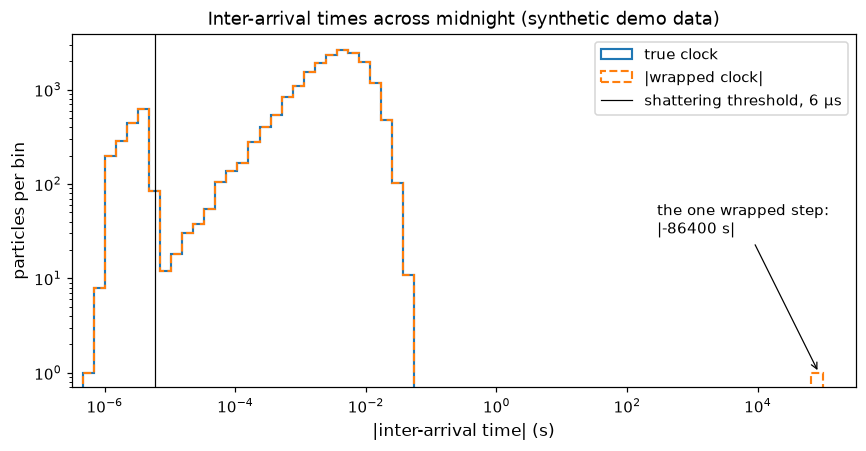

In [4]:
THRESH = 6e-6
ia_true = np.diff(t_true)
ia_wrap = np.diff(t_clock)

def shattering_removed(ia, thresh=THRESH):
    return int(np.sum(ia < thresh))     # a naive filter: negative counts as "too soon"

def sizedist_like(ia, thresh=THRESH):
    ia = ia.copy()
    rej_I = int(np.sum(ia < 0))         # still-negative values are rejected as 'I'
    ia[ia < 0] = 0
    return rej_I, int(np.sum((ia > 0) & (ia < thresh)))

print("naive shattering filter removes:  true clock", shattering_removed(ia_true),
      "| wrapped clock", shattering_removed(ia_wrap))
print("sizeDist-like ('I' rejects, shattered):  true", sizedist_like(ia_true),
      "| wrapped", sizedist_like(ia_wrap))

fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.logspace(-6.5, 5.5, 72)      # the data run from ~1e-6 s to the ~86 400 s wrap
ax.hist(np.abs(ia_true), bins=bins, histtype="step", lw=1.4, label="true clock")
ax.hist(np.abs(ia_wrap), bins=bins, histtype="step", ls="--", lw=1.4,
        label="|wrapped clock|")
ax.axvline(THRESH, color="k", lw=0.8, label="shattering threshold, 6 µs")
jump = abs(ia_wrap[i_mid - 1])
ax.annotate(f"the one wrapped step:\n|{ia_wrap[i_mid - 1]:.0f} s|", xy=(jump, 1),
            xytext=(jump / 300, 30), fontsize=10,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(bins[0], bins[-1])
ax.set_ylim(0.7, None)
ax.set_xlabel("|inter-arrival time| (s)", fontsize=11)
ax.set_ylabel("particles per bin", fontsize=11)
ax.tick_params(labelsize=10)
ax.set_title("Inter-arrival times across midnight (synthetic demo data)", fontsize=12)
ax.legend(fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()

*Figure 1. Histogram of the absolute gap between successive particles, for 20 000 synthetic arrivals that cross midnight. The solid and dashed lines coincide everywhere except one bin: the single step where the time-of-day clock wraps, about 86 400 s backwards (arrow). The black line is the 6 µs shattering threshold; bursts of fragments sit to its left.*

One midnight costs one particle. A counter that wraps every few minutes over a long flight costs one per
wrap, and a **wrong-sized** correction is worse: a span far smaller than the drop leaves the difference
negative, and one far larger turns it into a gap of minutes that no shattering threshold flags but that
breaks any per-second accounting built on the times. The next cell applies a counter-style span to a
midnight drop.

In [5]:
wrong_span = (2**24 - 1) * (100 / 1e6 / 200)   # a 24-bit counter span for res 100 um, tasMax 200 m/s
ia_bad = ia_wrap.copy()
ia_bad[ia_bad < 0] += wrong_span
print(f"wrong span {wrong_span:.2f} s: the jump becomes {ia_bad[i_mid-1]:.1f} s (still negative)")

wrong span 8.39 s: the jump becomes -86391.6 s (still negative)


## 5. The correction's idea

Restore monotonic time **before** the inter-arrival times are formed: at every backwards step, add the
step size (86400 s for a time of day, the counter span for a counter) to that particle and every one after
it, cumulatively. The processing then runs unmodified on the corrected copy, and the correction never
edits the product's numbers.

In [6]:
def corrected_times(t, step=86400.0, below=0.0):
    t = np.asarray(t, float).copy()
    d = np.diff(t)
    offset = np.concatenate([[0.0], np.cumsum(np.where(d < below, step, 0.0))])
    return t + offset

t_fixed = corrected_times(t_clock)
print("max |fixed - true| (s):", float(np.max(np.abs(t_fixed - t_true))))
print("naive shattering count after the fix:", shattering_removed(np.diff(t_fixed)),
      "(true clock:", shattering_removed(ia_true), ")")

max |fixed - true| (s): 0.0
naive shattering count after the fix: 1647 (true clock: 1647 )


Set the step test (`below`) from the class found in section 3: correcting sub-second jitter by
86400 s would invent a day-long gap.

## 6. Doing this on your own data

Edit the line below (path and variable name of the per-particle time, read with xarray; in a UIOOPS
particle file this is `Time_in_seconds`, and the per-second `Time` in HHMMSS tells you whether the flight
crosses midnight). Run the classifier, then choose the step from the class. **Remedy:** rerun the
processing with the correction applied to the input; never edit the product's numbers in place.

In [7]:
PARTICLE_TIME = None   # e.g. ("my_particle_file.nc", "Time_in_seconds")

def load(spec):
    import xarray as xr
    path, var = spec
    with xr.open_dataset(path) as ds:
        return np.asarray(ds[var].values, float).ravel()

t = load(PARTICLE_TIME) if PARTICLE_TIME else t_clock
rows = backward_steps(t)
kinds = {}
for _, _, k in rows:
    kinds[k] = kinds.get(k, 0) + 1
print(f"{t.size} particles, {len(rows)} backward steps")
for k, v in sorted(kinds.items()):
    print(f"  {k:22s} {v}")
if rows:
    print("largest drop: %.4f s at particle %d" % max((r[1], r[0]) for r in rows))

20000 particles, 1 backward steps
  midnight (~86400 s)    1
largest drop: 86399.9957 s at particle 8847
